In [1]:
import torch
import torch.nn as nn
import torch.optim
from torchvision import datasets,transforms,models
from torch.utils.data import Dataset,DataLoader

In [2]:
!pip install optuna
import optuna

In [3]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module='PIL.Image')

In [4]:
# set random seeds for reproducibility
torch.manual_seed(42)

In [5]:
# check for gpu
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [6]:
import zipfile
file=zipfile.ZipFile('/content/archive (2).zip')
file.extractall('/content')
file.close()

In [7]:
IMG_SIZE=224
batch_size=128
Data_Dir='/content/Final Dataset'

# Transforms for ImageFolder (only resizing, no augmentation, no ToTensor/Normalize yet)
# This prepares PIL Images of a consistent size for extraction into lists.
initial_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
])

initial_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
])

# Full transforms for CustomDataset (including all augmentations, ToTensor and Normalize)
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),
    transforms.GaussianBlur(3),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [37]:
train_dataset=datasets.ImageFolder(Data_Dir,transform=train_transform)
print(f"Dataset created from: {Data_Dir}")

Dataset created from: /content/Final Dataset


In [38]:
print(train_dataset.class_to_idx)

{'Fake': 0, 'Real': 1}


In [8]:
from sklearn.model_selection import train_test_split

# Create a full dataset from the Data_Dir
# This dataset will be used to extract all images and labels before splitting
# We use initial_train_transform which only resizes, not ToTensor/Normalize yet
full_dataset = datasets.ImageFolder(Data_Dir, transform=initial_train_transform)

# Extract all features (PIL Images) and labels from the full dataset
X_full_list = []
y_full_list = []
for i in range(len(full_dataset)):
    img, label = full_dataset[i]
    X_full_list.append(img)
    y_full_list.append(label)

# Perform train-test split
# Using stratify to maintain class distribution in both train and test sets
x_train, x_test, y_train, y_test = train_test_split(
    X_full_list, y_full_list, test_size=0.2, random_state=42, stratify=y_full_list
)

print(f"Original dataset size: {len(X_full_list)}")
print(f"Training samples after split: {len(x_train)}")
print(f"Test samples after split: {len(x_test)}")

# Store class_to_idx and idx_to_class for later use in custom dataset or plotting
class_to_idx = full_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

Original dataset size: 12890
Training samples after split: 10312
Test samples after split: 2578


In [11]:
len(x_train),len(x_test),len(y_train),len(y_test)

(10312, 2578, 10312, 2578)

In [12]:
# import torch
# import torch.nn as nn
# from torchvision import models

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # Load pretrained Vision Transformer (ViT)
# # Using vit_b_16 (Vision Transformer Base, patch size 16x16)
# model = models.vit_b_16(pretrained=True)

In [13]:
# # Freeze all parameters in the Vision Transformer's encoder (feature extractor)
# for param in model.encoder.parameters():
#     param.requires_grad = False

In [14]:
print("Class mapping:", idx_to_class)

Class mapping: {0: 'Fake', 1: 'Real'}


In [15]:
# import torch
# from torch.utils.data import WeightedRandomSampler

# # correct labels
# targets = torch.tensor(y_train)

# # count class samples
# class_sample_count = torch.tensor([
#     (targets == t).sum() for t in torch.unique(targets)
# ], dtype=torch.float)

# # compute weights
# class_weights = 1. / class_sample_count
# sample_weights = torch.tensor([class_weights[t] for t in targets])

# # sampler
# sampler = WeightedRandomSampler(
#     weights=sample_weights,
#     num_samples=len(sample_weights),
#     replacement=True
# )

# print("WeightedRandomSampler created successfully.")

In [9]:
from torch.utils.data import Dataset
import torch

class CustomDataset(Dataset):
    def __init__(self, features, labels, transform):
        self.features = features  # list of PIL Images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        image = self.features[idx]
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [17]:
train_dataset = CustomDataset(x_train, y_train, transform=train_transform)
test_dataset  = CustomDataset(x_test, y_test, transform=test_transform)
print("CustomDatasets created using extracted features and labels.")

# Update train_loader to use the new CustomDataset
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True, # Shuffle is fine since sampler is not active
    num_workers=0, # Set num_workers to 0 to prevent multiprocessing issues in Colab
    pin_memory=True
)

# Update test_loader to use the new CustomDataset
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders updated to use CustomDataset instances.")

CustomDatasets created using extracted features and labels.
DataLoaders updated to use CustomDataset instances.


In [18]:
# class CNN(nn.Module):
#     def __init__(self):
#         super(CNN, self).__init__()

#         self.features = nn.Sequential(
#             nn.Conv2d(3, 32, kernel_size=3, padding=1),
#             nn.ReLU(),
#             nn.BatchNorm2d(32),
#             nn.MaxPool2d(2, 2),

#             nn.Conv2d(32, 64, kernel_size=3, padding=1),
#             nn.ReLU(),
#             nn.BatchNorm2d(64),
#             nn.MaxPool2d(2, 2),

#             nn.AdaptiveAvgPool2d((7, 7))
#         )

#         self.classifier = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(64 * 7 * 7, 256),
#             nn.ReLU(),
#             nn.Dropout(0.4),
#             nn.Linear(256, 128),
#             nn.ReLU(),
#             nn.Dropout(0.4),
#             nn.Linear(128, 2)
#         )

#     def forward(self, x):
#         x = self.features(x)
#         x = self.classifier(x)
#         return x

In [19]:
# using pretrained model
import torchvision.models as models
restnet = models.resnet18(pretrained=True)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [20]:
restnet

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [21]:
# Freeze all parameters in the EfficientNet's feature extractor
for param in restnet.parameters():
    param.requires_grad = False

# The new classifier head (assigned in a later cell) will have requires_grad=True by default,
# so its parameters will be trainable by the optimizer.

In [22]:
restnet.fc=nn.Sequential(
    nn.Linear(in_features=512, out_features=1024, bias=True),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.5, inplace=False),
    nn.Linear(in_features=1024, out_features=512, bias=True),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.5, inplace=False),
    nn.Linear(in_features=512, out_features=2, bias=True)
).to(device)

In [23]:
# model=vgg16.to(device)
# This cell is now redundant as the model will be moved to device after classifier modification.

In [24]:
# model = model.to(device)
# This cell is now redundant.

In [25]:
model = restnet.to(device)

In [26]:
epochs=15
learning_rate=0.01

In [27]:
import torch
import torch.nn as nn
import torch.optim as optim

# Model (EfficientNet-B0 is already defined and modified)
# model = CNN().to(device) # This line was removed as it was re-initializing the model
# model=CNN().to(device)
# Loss function
loss_fn = nn.CrossEntropyLoss()

# Optimizer (will be defined after model is moved to device)
# optimizer = optim.Adam(
#     model.fc.parameters(),
#     lr=learning_rate,
# )

In [28]:
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=learning_rate,
)

In [29]:
print(f"Training started on {device}")

for epoch in range(epochs):
    # ---------------- TRAIN ----------------
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # accuracy
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # ---------------- PRINT ----------------
    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {train_loss:.4f}, "
          f"Acc: {train_acc*100:.2f}%")

print("Finished Training")

Training started on cuda
Epoch [1/5] Loss: 1.5939, Acc: 60.91%
Epoch [2/5] Loss: 0.5535, Acc: 69.75%
Epoch [3/5] Loss: 0.5524, Acc: 69.22%
Epoch [4/5] Loss: 0.5550, Acc: 68.73%
Epoch [5/5] Loss: 0.5429, Acc: 70.33%
Finished Training


In [30]:
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [31]:
correct = 0
total = 0

with torch.no_grad(): # Disable gradient calculations for evaluation
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the model on the {len(test_dataset)} test images: {100 * correct / total:.2f}%')

Accuracy of the model on the 2578 test images: 77.35%


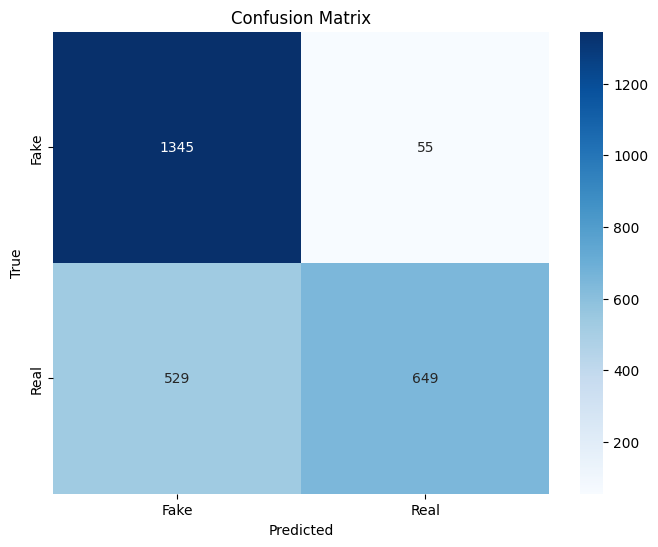

Confusion Matrix:
[[1345   55]
 [ 529  649]]


In [32]:
from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=idx_to_class.values(), yticklabels=idx_to_class.values())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

print("Confusion Matrix:")
print(cm)

In [33]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(all_labels, all_preds, target_names=idx_to_class.values())

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

        Fake       0.72      0.96      0.82      1400
        Real       0.92      0.55      0.69      1178

    accuracy                           0.77      2578
   macro avg       0.82      0.76      0.76      2578
weighted avg       0.81      0.77      0.76      2578



### Hyperparameter Optimization with Optuna

To find optimal hyperparameters for our ResNet classifier, we will use Optuna. Optuna automates the hyperparameter optimization process by defining an `objective` function that takes a `trial` object. Within this function, we'll sample different hyperparameters (like learning rate, hidden layer sizes, dropout rates), build and train a model with them, and then return a metric (e.g., accuracy) for Optuna to optimize.

In [10]:
from sklearn.model_selection import train_test_split

# Split the existing training data into new training and validation sets
x_train_split, x_val, y_train_split, y_val = train_test_split(
    X_full_list, y_full_list, test_size=0.2, random_state=42, stratify=y_full_list
)

print(f"Original training samples: {len(x_train)}")
print(f"New training samples: {len(x_train_split)}")
print(f"Validation samples: {len(x_val)}")

# Create CustomDatasets for the new splits
train_dataset_split = CustomDataset(x_train_split, y_train_split, transform=train_transform)
val_dataset = CustomDataset(x_val, y_val, transform=test_transform)

# Create DataLoaders for the new splits
train_loader = DataLoader(
    train_dataset_split,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train-validation split complete and DataLoaders updated/created.")

Original training samples: 10312
New training samples: 10312
Validation samples: 2578
Train-validation split complete and DataLoaders updated/created.


In [13]:
def objective(trial):

    import torch.optim as optim # Added this line

    # Initialize a fresh model for each trial to ensure independence
    trial_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Freeze all parameters in the ResNet's feature extractor
    for param in trial_model.parameters():
        param.requires_grad = False

    # Unfreeze the last convolutional block (layer4) to allow fine-tuning
    # This is a common practice in transfer learning
    for param in trial_model.layer4.parameters():
        param.requires_grad = True

    # Hyperparameters to tune for the new classifier head
    n_hidden_1 = trial.suggest_int('n_hidden_1', 256, 1024, step=256)
    dropout_rate_1 = trial.suggest_float('dropout_rate_1', 0.2, 0.6)
    n_hidden_2 = trial.suggest_int('n_hidden_2', 128, 512, step=128)
    dropout_rate_2 = trial.suggest_float('dropout_rate_2', 0.2, 0.6)
    lr = trial.suggest_float('lr', 1e-5, 1e-3, log=True)

    # Replace the fully connected layer with a new classifier head
    trial_model.fc = nn.Sequential(
        nn.Linear(in_features=512, out_features=n_hidden_1, bias=True),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout_rate_1, inplace=False),
        nn.Linear(in_features=n_hidden_1, out_features=n_hidden_2, bias=True),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout_rate_2, inplace=False),
        nn.Linear(in_features=n_hidden_2, out_features=2, bias=True)
    )

    trial_model.to(device)

    # Optimizer, only for trainable parameters (the new classifier head and unfeezed layer4)
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, trial_model.parameters()),
        lr=lr
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)
    loss_fn = nn.CrossEntropyLoss()

    # Training loop (5 epochs for each trial)
    for epoch in range(5):
        trial_model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = trial_model(images)
            loss = loss_fn(outputs, labels)

            loss.backward()
            optimizer.step()

        scheduler.step()

    # Validation (using val_loader, not test_loader)
    trial_model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = trial_model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    return accuracy

In [14]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

print("Best trial:")
print(study.best_trial.params)

[I 2026-05-03 11:32:09,708] A new study created in memory with name: no-name-d69bc6fc-4cdc-4eca-ab93-f030fc889c5a
[I 2026-05-03 11:38:42,272] Trial 0 finished with value: 0.843289371605896 and parameters: {'n_hidden_1': 256, 'dropout_rate_1': 0.2854575726052607, 'n_hidden_2': 128, 'dropout_rate_2': 0.4440487252267902, 'lr': 1.436057335710263e-05}. Best is trial 0 with value: 0.843289371605896.
[I 2026-05-03 11:45:32,069] Trial 1 finished with value: 0.9460822342901474 and parameters: {'n_hidden_1': 1024, 'dropout_rate_1': 0.3308229901230266, 'n_hidden_2': 256, 'dropout_rate_2': 0.45737262845411847, 'lr': 0.0009293600471159167}. Best is trial 1 with value: 0.9460822342901474.
[I 2026-05-03 11:52:07,900] Trial 2 finished with value: 0.9150504266873546 and parameters: {'n_hidden_1': 1024, 'dropout_rate_1': 0.2807454705746909, 'n_hidden_2': 128, 'dropout_rate_2': 0.3390126726945726, 'lr': 4.282701665896763e-05}. Best is trial 1 with value: 0.9460822342901474.
[I 2026-05-03 11:58:34,816] Tr

Best trial:
{'n_hidden_1': 1024, 'dropout_rate_1': 0.3308229901230266, 'n_hidden_2': 256, 'dropout_rate_2': 0.45737262845411847, 'lr': 0.0009293600471159167}


### Training with Best Hyperparameters

Now, let's train a new model using the best hyperparameters identified by Optuna.

In [15]:
# Extract best hyperparameters from the Optuna study
best_params = study.best_trial.params

n_hidden_1_best = best_params['n_hidden_1']
dropout_rate_1_best = best_params['dropout_rate_1']
n_hidden_2_best = best_params['n_hidden_2']
dropout_rate_2_best = best_params['dropout_rate_2']
lr_best = best_params['lr']

print(f"Best Hyperparameters: {best_params}")

Best Hyperparameters: {'n_hidden_1': 1024, 'dropout_rate_1': 0.3308229901230266, 'n_hidden_2': 256, 'dropout_rate_2': 0.45737262845411847, 'lr': 0.0009293600471159167}


In [16]:
# Initialize a fresh ResNet18 model
model_optimized = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all parameters in the feature extractor
for param in model_optimized.parameters():
    param.requires_grad = False

# Unfreeze the last convolutional block (layer4)
for param in model_optimized.layer4.parameters():
    param.requires_grad = True

# Replace the fully connected layer with the optimized head
model_optimized.fc = nn.Sequential(
    nn.Linear(in_features=512, out_features=n_hidden_1_best, bias=True),
    nn.ReLU(inplace=True),
    nn.Dropout(p=dropout_rate_1_best, inplace=False),
    nn.Linear(in_features=n_hidden_1_best, out_features=n_hidden_2_best, bias=True),
    nn.ReLU(inplace=True),
    nn.Dropout(p=dropout_rate_2_best, inplace=False),
    nn.Linear(in_features=n_hidden_2_best, out_features=2, bias=True)
)

model_optimized.to(device)

# Define optimizer and loss function with best learning rate
optimizer_optimized = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_optimized.parameters()),
    lr=lr_best
)
loss_fn_optimized = nn.CrossEntropyLoss()

print("Optimized model initialized and moved to device.")

Optimized model initialized and moved to device.


In [17]:
epochs_final = 15 # Use the full number of epochs for final training

print(f"Training optimized model on {device} for {epochs_final} epochs...")

for epoch in range(epochs_final):
    # --- Training Phase ---
    model_optimized.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_optimized.zero_grad()
        outputs = model_optimized(images)
        loss = loss_fn_optimized(outputs, labels)
        loss.backward()
        optimizer_optimized.step()

        train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    avg_train_loss = train_loss / len(train_loader)
    acc_train = correct_train / total_train

    # --- Validation Phase ---
    model_optimized.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_optimized(images)
            loss = loss_fn_optimized(outputs, labels)

            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    avg_val_loss = val_loss / len(val_loader)
    acc_val = correct_val / total_val

    print(f"Epoch [{epoch+1}/{epochs_final}], "
          f"Train Loss: {avg_train_loss:.4f}, Train Acc: {acc_train*100:.2f}%, "
          f"Val Loss: {avg_val_loss:.4f}, Val Acc: {acc_val*100:.2f}%")

print("Finished final training with optimized hyperparameters.")

Training optimized model on cuda for 15 epochs...
Epoch [1/15], Train Loss: 0.3458, Train Acc: 84.29%, Val Loss: 0.3439, Val Acc: 86.15%
Epoch [2/15], Train Loss: 0.2349, Train Acc: 90.08%, Val Loss: 0.2140, Val Acc: 90.54%
Epoch [3/15], Train Loss: 0.1895, Train Acc: 92.31%, Val Loss: 0.2052, Val Acc: 91.08%
Epoch [4/15], Train Loss: 0.1646, Train Acc: 93.35%, Val Loss: 0.1714, Val Acc: 93.13%
Epoch [5/15], Train Loss: 0.1519, Train Acc: 93.89%, Val Loss: 0.1715, Val Acc: 93.17%
Epoch [6/15], Train Loss: 0.1288, Train Acc: 95.11%, Val Loss: 0.1662, Val Acc: 93.79%
Epoch [7/15], Train Loss: 0.1184, Train Acc: 95.35%, Val Loss: 0.1486, Val Acc: 94.18%
Epoch [8/15], Train Loss: 0.1030, Train Acc: 95.88%, Val Loss: 0.1576, Val Acc: 94.65%
Epoch [9/15], Train Loss: 0.0971, Train Acc: 96.32%, Val Loss: 0.1797, Val Acc: 93.60%
Epoch [10/15], Train Loss: 0.0926, Train Acc: 96.68%, Val Loss: 0.2594, Val Acc: 91.78%
Epoch [11/15], Train Loss: 0.0851, Train Acc: 96.79%, Val Loss: 0.1916, Val Acc

In [18]:
torch.save(model_optimized.state_dict(), 'deepfake_resnet.pth')
print("Optimized model saved to deepfake_resnet.pth")

Optimized model saved to deepfake_resnet.pth
